# STAR Project – Exploring the Data

**Research question:** Does the benefit of small classes (K–3) last over time, up to grade 8 and high school?

**Data:** Project STAR, Tennessee. Students were randomly assigned to a **small class** (13–17),
a **regular class** (22–25) or a **regular class with a teacher aide**, from kindergarten (1985) to grade 3.
Scores were then followed up to grade 8, and high school graduation was collected later.
Source: Harvard Dataverse (hdl:1902.1/10766). Variable details: `starUsersGuide.pdf`.

**This notebook:** get to know the data before any analysis.
1. Load the data
2. The key variables
3. Who is in the data, and when?
4. Were the groups similar at the start?
5. Were small classes really small?
6. Math scores
7. Complications: missing data and switching
8. Summary

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

df = pd.read_spss("../data/raw/STAR_Students.sav")
df = df.copy()   # makes the table faster to work with

print(df.shape)  # (rows, columns)

(11601, 379)


**11,601 students** (one row each) and **379 variables**.

## 2. The key variables

Most column names start with the grade: `gk` = kindergarten, `g1`–`g8` = grades 1–8, `hs` = high school.
Out of 379 columns, we need only a few:

| Variable | Meaning | Grades |
|---|---|---|
| `gkclasstype` … `g3classtype` | Class type: small / regular / regular + aide (**the treatment**) | K–3 only |
| `gktmathss` … `g8tmathss` | Total math score (**the outcome**) | K–8 |
| `gkclasssize` | Number of students in the class | K |
| `gender`, `race`, `gkfreelunch` | Background. Free lunch = low-income family | – |
| `gkschid` | School ID (randomization was done **inside** each school) | K |
| `hsgrdcol` | Graduated high school (YES / NO) | HS |

**Important:** K–3 math was the Stanford test (SAT). Grades 4–8 used a different test (CTBS).
Scores jump between grade 3 and 4, so we only compare groups **within** the same grade.

We also create two helper columns:
- `first_classtype` – the class type the student got when they **entered** the study
- `entry_grade` – the grade in which they entered (some joined after kindergarten)

In [2]:
grades = ["gk", "g1", "g2", "g3", "g4", "g5", "g6", "g7", "g8"]
k3 = ["gk", "g1", "g2", "g3"]
grade_labels = ["K", "1", "2", "3", "4", "5", "6", "7", "8"]

classtype_cols = [f"{g}classtype" for g in k3]
math_cols = [f"{g}tmathss" for g in grades]

df["first_classtype"] = df[classtype_cols].astype(object).bfill(axis=1).iloc[:, 0]
df["entry_grade"] = np.array(grade_labels[:4])[df[classtype_cols].notna().values.argmax(axis=1)]

df[["stdntid", "gender", "race", "gkfreelunch", "first_classtype", "entry_grade", "gktmathss", "g8tmathss", "hsgrdcol"]].head()

,stdntid,gender,race,gkfreelunch,first_classtype,entry_grade,gktmathss,g8tmathss,hsgrdcol
0,10000.0,MALE,WHITE,NaN,REGULAR + AIDE CLASS,1,NaN,NaN,NaN
1,10001.0,MALE,WHITE,NON-FREE LUNCH,REGULAR + AIDE CLASS,K,NaN,782.0,NaN
2,10002.0,FEMALE,BLACK,NaN,REGULAR + AIDE CLASS,3,NaN,645.0,NO
3,10003.0,MALE,WHITE,NaN,REGULAR CLASS,1,NaN,768.0,YES
4,10004.0,FEMALE,BLACK,NaN,REGULAR + AIDE CLASS,2,NaN,791.0,NO


## 3. Who is in the data, and when?

- **Left table:** in which grade did students enter the study, and with which class type?
- **Right table / chart:** how many students have a math score in each grade?

first_classtype  REGULAR + AIDE CLASS  REGULAR CLASS  SMALL CLASS  Total
entry_grade                                                             
1                                 903           1026          385   2314
2                                 659            654          366   1679
3                                 456            454          373   1283
K                                2231           2194         1900   6325
Total                            4249           4328         3024  11601 

K    5871
1    6598
2    6065
3    6077
4    4331
5    2589
6    6422
7    4888
8    6213
dtype: int64


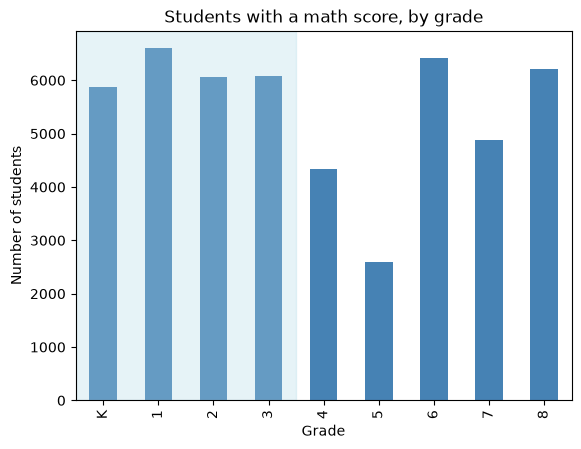

In [3]:
entry = pd.crosstab(df["entry_grade"], df["first_classtype"], margins=True, margins_name="Total")
print(entry, "\n")

n_scores = pd.Series({lab: df[col].notna().sum() for lab, col in zip(grade_labels, math_cols)})
print(n_scores)

n_scores.plot(kind="bar", color="steelblue", title="Students with a math score, by grade")
plt.axvspan(-0.5, 3.5, color="lightblue", alpha=0.3)   # experiment years
plt.xlabel("Grade")
plt.ylabel("Number of students")
plt.show()

**What we see:**
- Only about half of the students started in kindergarten. Many joined in grade 1 (kindergarten was not mandatory in Tennessee then, User Guide), and some in grades 2–3.
- In every grade about half of the 11,601 students have no score.
- **Grade 4** is lower: 17 STAR schools did not take part in the new state test that year (User Guide, p. 1.10).
- **Grade 5** is much lower: matching STAR students with state records did not work well that year, and the User Guide says there is no clear explanation. We look at this in a separate notebook.

## 4. Were the groups similar at the start?

If randomization worked, the three class types should have a similar background.
We check kindergarten students only (the original randomization).

In [4]:
k = df[df["gkclasstype"].notna()]

def pct(col, value):
    """% of students (with data) in each class type who have this value."""
    return k.groupby("gkclasstype", observed=True)[col].apply(lambda s: (s == value).sum() / s.notna().sum() * 100)

balance = pd.DataFrame({
    "% free lunch": pct("gkfreelunch", "FREE LUNCH"),
    "% white": pct("race", "WHITE"),
    "% girls": pct("gender", "FEMALE"),
    "Number of students": k.groupby("gkclasstype", observed=True).size(),
}).round(1).T
balance

gkclasstype,REGULAR + AIDE CLASS,REGULAR CLASS,SMALL CLASS
% free lunch,50.3,47.7,47.1
% white,65.8,67.2,68.1
% girls,48.3,49.0,48.6
Number of students,2231.0,2194.0,1900.0


**What we see:** the three groups look very similar (about half free lunch, about two thirds white, about half girls).
This is a sign that the randomization worked: differences in scores later are likely caused by class type, not by background.

## 5. Were small classes really small?

Check that the treatment actually happened: class size by class type, in kindergarten.

Schools: 79 | Kindergarten classes: 325 

                      mean   min   max
gkclasstype                           
REGULAR + AIDE CLASS  22.8  15.0  28.0
REGULAR CLASS         22.4  16.0  27.0
SMALL CLASS           15.1  12.0  17.0


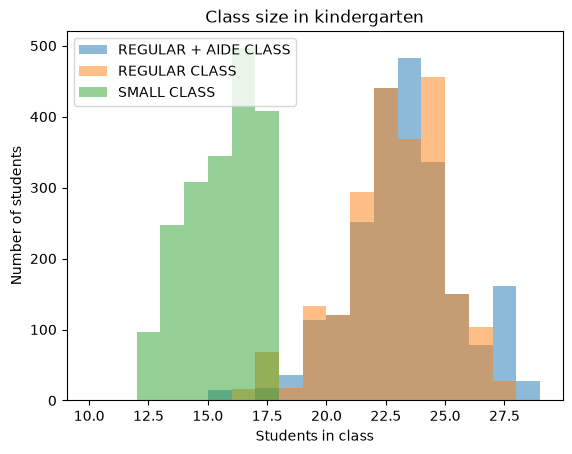

In [5]:
print("Schools:", df["gkschid"].nunique(), "| Kindergarten classes:", df["gktchid"].nunique(), "\n")
print(k.groupby("gkclasstype", observed=True)["gkclasssize"].describe()[["mean", "min", "max"]].round(1))

for ctype, group in k.groupby("gkclasstype", observed=True):
    plt.hist(group["gkclasssize"].dropna(), bins=range(10, 30), alpha=0.5, label=ctype)
plt.title("Class size in kindergarten")
plt.xlabel("Students in class")
plt.ylabel("Number of students")
plt.legend()
plt.show()

**What we see:** 79 schools and 325 kindergarten classes. Small classes had about 15 students on average,
regular classes about 22–23. The two histograms barely overlap – the treatment really happened.

## 6. Math scores

**Top:** basic statistics of the math score in each grade.
**Bottom:** average score by first class type, in each grade.

In [6]:
desc = df[math_cols].describe().T[["count", "mean", "std", "min", "max"]].round(1)
desc.index = grade_labels
desc

,count,mean,std,min,max
K,5871.0,485.4,47.7,288.0,626.0
1,6598.0,530.5,43.1,404.0,676.0
2,6065.0,580.6,44.6,441.0,721.0
3,6077.0,618.0,39.8,487.0,774.0
4,4331.0,707.0,46.5,492.0,840.0
5,2589.0,734.6,42.1,532.0,857.0
6,6422.0,751.9,44.0,553.0,874.0
7,4888.0,765.4,43.2,602.0,920.0
8,6213.0,782.3,48.8,572.0,920.0


first_classtype  REGULAR + AIDE CLASS  REGULAR CLASS  SMALL CLASS
K                               482.8          483.2        490.9
1                               528.8          526.7        538.4
2                               578.0          578.8        587.0
3                               615.2          616.9        623.3
4                               703.9          707.2        710.6
5                               731.8          733.9        739.1
6                               750.7          751.1        754.7
7                               763.3          764.0        770.3
8                               779.8          782.2        786.0


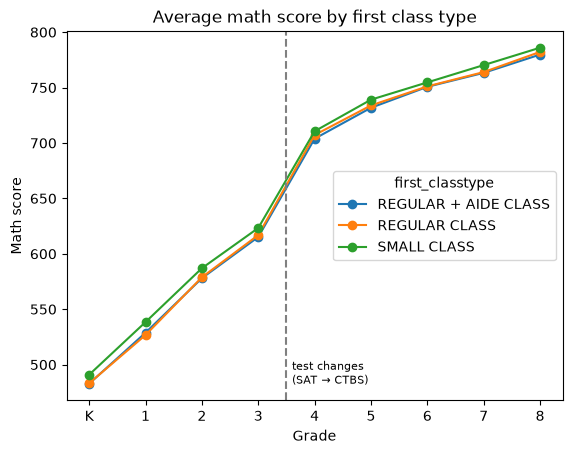

In [7]:
means = df.groupby("first_classtype")[math_cols].mean().T.round(1)
means.index = grade_labels
print(means)

means.plot(marker="o", title="Average math score by first class type")
plt.axvline(3.5, color="gray", linestyle="--")
plt.text(3.6, means.values.min(), "test changes\n(SAT → CTBS)", fontsize=8)
plt.xlabel("Grade")
plt.ylabel("Math score")
plt.show()

**What we see:**
- Scores go up every year (students learn), with a jump between grade 3 and 4 because the test changed.
- In **every** grade, students who started in a small class have the highest average.
  The two regular class types are almost the same.
- The gap is about 8 points in K, about 12 in grade 1, and about 4 in grade 8.
  The next step is to measure this gap properly, with confidence intervals (notebook 03).

## 7. Complications

**a. Missing data:** % of students with a math score in each grade, by first class type.
If one group loses more students than the others, the comparison may be biased.

**b. Switching:** did students stay in the class type they got in K? (rows = K, columns = grade 1)

In [8]:
has_score = df.groupby("first_classtype")[math_cols].apply(lambda d: d.notna().mean() * 100).round(1)
has_score.columns = grade_labels
has_score

,K,1,2,3,4,5,6,7,8
first_classtype,,,,,,,,,
REGULAR + AIDE CLASS,48.9,56.5,52.5,52.6,36.1,21.9,55.2,41.6,53.8
REGULAR CLASS,47.0,57.1,53.0,51.9,37.4,22.0,54.8,42.8,53.5
SMALL CLASS,58.3,57.1,51.0,52.7,39.1,23.4,56.4,42.0,53.2


In [9]:
pd.crosstab(df["gkclasstype"], df["g1classtype"], dropna=False)

g1classtype,REGULAR + AIDE CLASS,REGULAR CLASS,SMALL CLASS
gkclasstype,,,
NaN,903,1026,385
REGULAR + AIDE CLASS,706,761,122
REGULAR CLASS,663,737,126
SMALL CLASS,48,60,1292


**What we see:**
- **Missing data:** about half of the students are missing in each grade, and more in grades 4–5.
  Compare the rows: if they are close, dropout is similar across class types.
  (In K–2 the numbers are lower partly because some students had not joined the study yet.)
- **Switching:** most students who started in a small class stayed in one (1,292 out of 1,400).
  But about 250 students moved from a regular class to a small one, which was not part of the plan.
  Also, more than 2,300 new students joined in grade 1.

## 8. Summary

1. **The data:** 11,601 students, 79 schools. Treatment = class type (K–3). Outcome = math score (K–8).
2. **The experiment worked:** the groups had a similar background, and small classes really were smaller.
3. **First look at the effect:** small classes score higher in every grade. The gap is biggest in grade 1 and smaller later, but it does not disappear.
4. **Complications for later:**
   - About half of the students are missing in each grade (and grade 5 is a special case).
   - Some students switched class type or joined late.
   - Different tests before and after grade 4.
   - Randomization was inside schools, so later we should account for school.

**Open questions:**
-